In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = project_root / "data" / "processed" / "netflix_cleaned_dataset.csv"
df = pd.read_csv(data_path)

print("Shape:", df.shape)
print("Release year range:", df["release_year"].min(), "to", df["release_year"].max())
print("Missing release years: ", df["release_year"].isna().sum())

Shape: (8790, 10)
Release year range: 1925 to 2021
Missing release years:  0


In [5]:
yearly_releases = (
    df.groupby("release_year")
    .size()
    .sort_index()
    .rename("title_count")
)

display(yearly_releases.tail(15).to_frame())

,title_count
release_year,
2007,88
2008,135
2009,152
2010,192
2011,185
2012,236
2013,286
2014,352
2015,555


In [6]:
yearly_trends = yearly_releases.to_frame()
yearly_trends["change_in_titles"] = yearly_trends["title_count"].diff()
yearly_trends["change_percent"] = (
    yearly_trends["title_count"].pct_change().mul(100).round(1)
)

display(yearly_trends.loc[2015:2021])

,title_count,change_in_titles,change_percent
release_year,,,
2015,555,203.0,57.7
2016,901,346.0,62.3
2017,1030,129.0,14.3
2018,1146,116.0,11.3
2019,1030,-116.0,-10.1
2020,953,-77.0,-7.5
2021,592,-361.0,-37.9


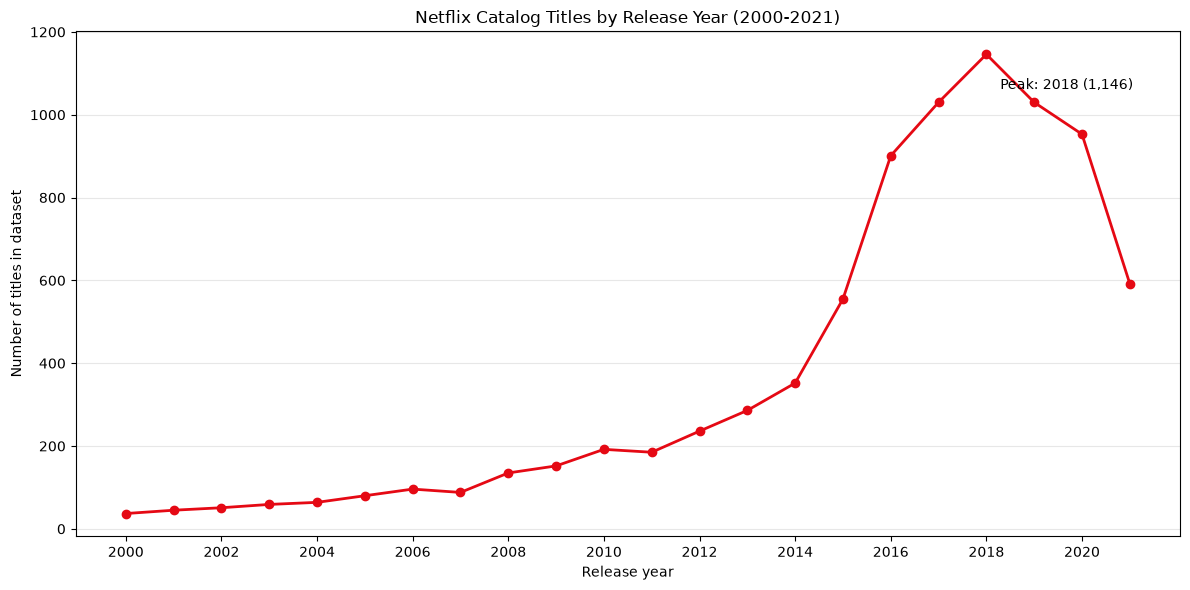

In [11]:
# percentage period where catalog had most titles
recent_releases = yearly_releases.loc[2000:]

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(
    recent_releases.index,
    recent_releases.values,
    marker="o",
    linewidth=2,
    color="#E50914"
)

peak_year = recent_releases.idxmax()
peak_count = recent_releases.max()
ax.annotate (
    f"Peak: {peak_year} ({peak_count:,})",
    xy=(peak_year, peak_count),
    xytext=(10, -25),
    textcoords="offset points"
)

ax.set_title("Netflix Catalog Titles by Release Year (2000-2021)")
ax.set_xlabel("Release year")
ax.set_ylabel("Number of titles in dataset")
ax.set_xticks(range(2000, 2022, 2))
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

# Key findings

- **Release-year trend:** The number of titles in this dataset rises through the 2000s and 2010s, peaking at 1,146 titles released in 2018.
- **Recent counts:** Counts decline to 1,030 in 2019, 953 in 2020, and 592 in 2021.

These counts describe titles in this dataset, not Netflix's annual production output. The 2021 decline may also reflect incomplete data for the latest year included.